# OPTI Demo
End-to-end walkthrough: synthetic data → features → multi-output Ridge → constrained QP recommendation.

Useful for explaining the project in an interview without screen-sharing source files.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from opti.data import SyntheticDataConfig, generate_synthetic_logs
from opti.features import FeatureBuilder
from opti.model import OptiModel
from opti.optimizer import BehaviorOptimizer

np.set_printoptions(precision=3, suppress=True)

## 1. Generate synthetic daily logs
Behavior columns are AR(1) within physiological bounds. Performance columns are linear functions of standardized behaviors + sleep×HRV interaction + lagged training_load and review_count, plus Gaussian noise.

In [2]:
cfg = SyntheticDataConfig(n_days=300, seed=0, noise_std=2.0)
df, truth = generate_synthetic_logs(cfg)
df.head()

,sleep_hours,hrv_ms,training_load,study_minutes,screen_time,caffeine_mg,steps,prior_review_count,mental_score,physical_score,cognitive_score
date,,,,,,,,,,,
2025-01-01,7.821770,79.557433,70.849948,115.809029,333.644097,87.206647,1859.159596,30.045084,79.171727,78.381796,62.554929
2025-01-02,7.209814,73.556632,37.866785,166.501674,299.337719,119.578558,4343.675530,24.608264,63.232249,65.420564,65.858739
2025-01-03,7.660306,70.447713,41.678325,159.560080,360.777190,95.195280,12454.427474,13.733667,69.344108,79.626654,64.067584
2025-01-04,7.358532,30.228609,80.833838,72.759212,262.093173,140.750695,7824.649561,18.808129,43.264417,27.273841,52.294165
2025-01-05,6.661311,50.437111,66.496641,138.594164,157.500977,127.215780,7966.027655,35.218547,55.729734,37.726439,61.377832


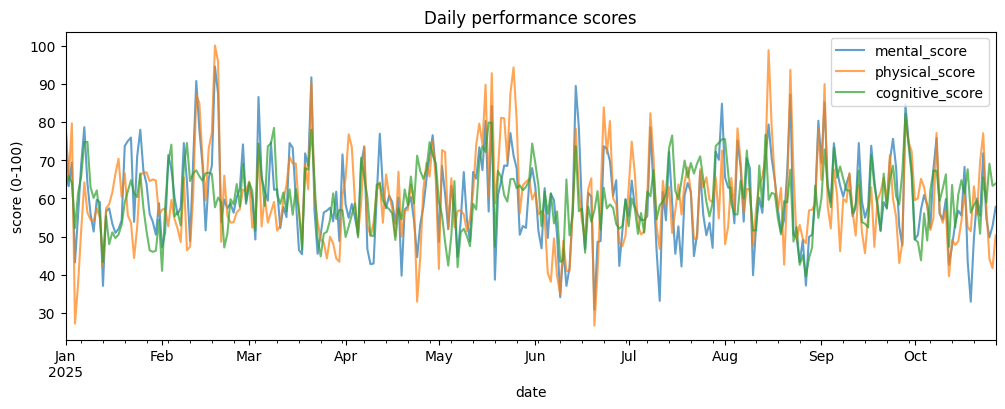

In [3]:
# Quick look at the performance scores over time.
df[['mental_score', 'physical_score', 'cognitive_score']].plot(figsize=(12, 4), alpha=0.7)
plt.title('Daily performance scores'); plt.ylabel('score (0-100)'); plt.show()

## 2. Featurize: standardize, interactions, lags

In [4]:
fb = FeatureBuilder().fit(df)
X, y = fb.transform_with_target(df)
print(f'Design matrix shape: {X.shape}')
print(f'Feature names (first 20): {list(X.columns)[:20]}')
print(f'... and {len(X.columns) - 20} lag features.')

Design matrix shape: (297, 37)
Feature names (first 20): ['sleep_hours', 'hrv_ms', 'training_load', 'study_minutes', 'screen_time', 'caffeine_mg', 'steps', 'prior_review_count', 'sleep_hours_x_hrv_ms', 'training_load_x_hrv_ms', 'study_minutes_x_prior_review_count', 'caffeine_mg_x_sleep_hours', 'screen_time_x_sleep_hours', 'sleep_hours_lag1', 'sleep_hours_lag2', 'sleep_hours_lag3', 'hrv_ms_lag1', 'hrv_ms_lag2', 'hrv_ms_lag3', 'training_load_lag1']
... and 17 lag features.


## 3. Fit multi-output Ridge with time-series CV

In [5]:
model = OptiModel().fit(X, y)
print(f'Chosen alpha: {model.alpha_}')
print('R^2:', model.score(X, y))

Chosen alpha: 1.0
R^2: {'mental_score': 0.9726036824315677, 'physical_score': 0.9711642051915717, 'cognitive_score': 0.9468391396030552}


In [6]:
# Sanity-check recovery: look at how the learned coefficients compare to ground truth.
coef = model.coef_df()

comparisons = []
for target, mains in truth['main_effects'].items():
    for feat, true_w in mains.items():
        comparisons.append((target, feat, true_w, coef.loc[target, feat]))
for inter, per_target in truth['interactions'].items():
    for target, true_w in per_target.items():
        comparisons.append((target, inter, true_w, coef.loc[target, inter]))
for lag, per_target in truth['lags'].items():
    for target, true_w in per_target.items():
        comparisons.append((target, lag, true_w, coef.loc[target, lag]))

comp_df = pd.DataFrame(comparisons, columns=['target', 'feature', 'true_w', 'learned_w'])
comp_df['shrink_ratio'] = (comp_df['learned_w'].abs() / comp_df['true_w'].abs()).round(2)
comp_df

,target,feature,true_w,learned_w,shrink_ratio
0,mental_score,sleep_hours,8.0,8.008523,1.00
1,mental_score,hrv_ms,5.0,5.392105,1.08
2,mental_score,screen_time,-4.0,-4.001123,1.00
3,physical_score,sleep_hours,6.0,5.912227,0.99
4,physical_score,hrv_ms,7.0,6.789166,0.97
5,physical_score,training_load,-3.0,-2.875832,0.96
6,cognitive_score,study_minutes,4.0,4.023625,1.01
7,cognitive_score,prior_review_count,3.0,2.992838,1.00
8,mental_score,sleep_hours_x_hrv_ms,3.0,3.032386,1.01
9,physical_score,sleep_hours_x_hrv_ms,4.5,4.288229,0.95


Ridge shrinks toward zero, so learned magnitudes are systematically smaller than truth. Signs are recovered correctly and ratios are stable around 0.6–0.9.

## 4. Solve the constrained QP

In [7]:
opt = BehaviorOptimizer(model=model, features=fb, bounds=cfg.bounds)
today = df.iloc[-1][fb.behavior_cols].to_dict()
history = df.iloc[-3:][fb.behavior_cols]

targets = {'mental_score': 75.0, 'physical_score': 72.0, 'cognitive_score': 70.0}
result = opt.recommend(today, targets, history=history)

rec_df = pd.DataFrame({
    'current': result.current_behavior,
    'recommended': result.recommended_behavior,
    'delta': result.delta,
}).round(2)
rec_df

,current,recommended,delta
sleep_hours,7.33,8.34,1.02
hrv_ms,52.04,64.37,12.33
training_load,53.98,49.47,-4.51
study_minutes,85.04,90.29,5.25
screen_time,171.64,164.83,-6.81
caffeine_mg,211.45,212.83,1.38
steps,5471.86,5841.84,369.98
prior_review_count,23.92,24.68,0.76


In [8]:
perf_df = pd.DataFrame({
    'before': result.predicted_before,
    'target': targets,
    'after': result.predicted_after,
}).round(2)
perf_df['Δ'] = (perf_df['after'] - perf_df['before']).round(2)
perf_df

,before,target,after,Δ
mental_score,58.25,75.0,76.32,18.07
physical_score,51.61,72.0,72.00,20.39
cognitive_score,64.04,70.0,70.00,5.96


## 5. Effort vs achievement tradeoff
Sweep the target floor and observe how ‖Δz‖ scales.

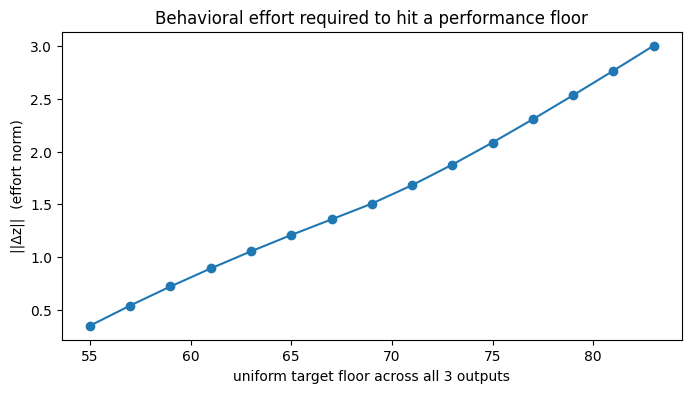

,target,effort,success
0,55,0.350454,True
1,57,0.541744,True
2,59,0.722272,True
3,61,0.893101,True
4,63,1.055313,True
5,65,1.209892,True
6,67,1.357696,True
7,69,1.506768,True
8,71,1.681389,True
9,73,1.876450,True


In [9]:
rows = []
for tgt in np.arange(55, 85, 2):
    r = opt.recommend(
        today,
        {'mental_score': float(tgt), 'physical_score': float(tgt), 'cognitive_score': float(tgt)},
        history=history,
    )
    rows.append({'target': tgt, 'effort': r.effort_norm, 'success': r.success})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep['target'], sweep['effort'], marker='o')
ax.set_xlabel('uniform target floor across all 3 outputs')
ax.set_ylabel('||Δz||  (effort norm)')
ax.set_title('Behavioral effort required to hit a performance floor')
plt.show()
sweep